# Same pixels, different physics — a sense of heft for robot arms

Two balls, **visually identical**: same radius, same color, same everything a
camera can see. One is solid and heavy; one is hollow and light. A policy
trained on pixels cannot tell them apart — but the throw that lands one of
them on a target sails the other one past it. Mass is not in the pixels.

It *is* in the dynamics. Once the arm holds the ball, its own joint telemetry
carries the missing information: the calibrated arm is a **force scale**.
This notebook is the whole loop, quantitatively, in simulation:

1. **The blind throw** — one open-loop throw tuned for the *expected* ball;
   the dense one falls short-and-wide, the hollow one overshoots.
2. **The heft** — ~0.2 s of coast telemetry → `identify_payload` recovers
   each ball's mass and centre of mass, with confidence intervals; the
   identifiability report says *before any fit* what a probe can and cannot
   resolve.
3. **Choosing the next poke** — `design_probe` gradient-optimizes the probe
   itself (differentiable optimal experiment design).
4. **The corrected throw** — re-tuned on the *identified* model (not the
   truth!), both balls land.
5. **Other senses** — a toss (restitution, differentiated *through* the
   bounces) and a squeeze (stiffness/damping).
6. **Per-object attestation** — same arm + different ball = different
   attested twin.

**Honest scope** (see `KNOWN_GAPS.md` §Object-side identification): this is
**simulation-tier** — the "real" balls are planted-parameter loopbacks (the
same pattern the joint-level sysid lane validates with, C-103), the grasp is
a rigid weld, and no vision/extraction pipeline is involved. The claims
exercised here are C-120 (payload ID), C-121 (probe design), C-122
(contact/impact ID).


In [1]:
import logging
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mujoco
import numpy as np

from jaxterity import zoo
from jaxterity.calibrate.active import Excitation, design_coast_excitation
from jaxterity.objects import (
    PayloadLoopbackLink,
    RigidPayload,
    attach_payload,
    design_probe,
    identify_payload,
    identify_restitution,
    identify_squeeze,
    payload_identifiability,
    predict_bounce_times,
    probe_information,
)

# jaxonomy announces every fresh simulator trace at INFO — informative in a
# terminal, clutter in a notebook. Warnings still come through.
logging.getLogger("jaxonomy").setLevel(logging.WARNING)

t_start = time.time()
arm = zoo.calibrated("so100")  # the calibrated arm IS the force scale
print("arm:", arm.name, "| calibration:", arm.calibration_state.value)

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


arm: so101_new_calib | calibration: calibrated


## The two balls

Same 2.3 cm radius, same look. What the camera sees is identical; what the
dynamics see is not. The **prior** is what vision alone can give you — a
guess from apparent size (here 0.12 kg, centred) — and it is all the blind
policy has.

| | radius | appearance | true mass | true CoM offset |
|---|---|---|---|---|
| ball **S** (solid) | 2.3 cm | identical | **0.30 kg** | (2, −5, 12) mm |
| ball **H** (hollow) | 2.3 cm | identical | **0.04 kg** | (0, 0, 3) mm |


In [2]:
# gripper_frame_link's origin is the fingertip TCP. The true grasp pocket —
# measured by nesting a sphere against the two jaws' render meshes — sits
# 2.6 cm along the frame's x-axis (the jaw-opening direction), not along the
# arm axis as one might guess.
GRASP = dict(attach_link="gripper_frame_link", offset=(-0.026, 0.0, -0.001))
prior = RigidPayload(mass=0.12, com=(0.0, 0.0, 0.0), **GRASP)  # vision's guess

TRUE = {
    "S": dict(mass=0.30, com=(0.002, -0.005, 0.012)),  # solid
    "H": dict(mass=0.04, com=(0.000, 0.000, 0.003)),  # hollow
}

# The "real" balls: seeded loopbacks that simulate the arm holding the TRUE
# ball — identify_payload must recover what was planted (C-103 pattern).
balls = {
    k: PayloadLoopbackLink(
        arm,
        prior,
        true_mass=v["mass"],
        true_com=v["com"],
        seed=i,
        noise_std=1e-4,
    )
    for i, (k, v) in enumerate(TRUE.items())
}

## Act 1 — the blind throw

The throw: the arm rigidly holds its extended pose (`with_welded_joints` —
the position servos, idealized) and slings the ball with the shoulder-pan
joint under a constant open-loop torque, releasing at cutoff. Ballistics do
the rest. Two knobs: **aim** (the starting pan
angle — an exact rotation of the landing point about the pan axis) and
**power** (the torque). Landings are always evaluated the physical way:
forward kinematics of the spinning arm, then ballistics — no shortcut map.

The blind policy tunes both knobs on the **prior** model. Physics: at the
same torque, a heavier ball both *lags in angle* and *releases slower* — so
it lands short **and** wide. The lighter ball does the opposite.


In [3]:
turret = arm.with_welded_joints(
    ("shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll", "gripper")
)
DT, T_REL = 0.005, 0.30
N_STEPS = int(T_REL / DT) + 3
K_REL = int(T_REL / DT) - 1
G = 9.81


def throw_model(mass, com=(0.0, 0.0, 0.0)):
    """Welded-pose turret holding a ball of the given inertials."""
    held = attach_payload(turret, RigidPayload(mass=mass, com=com, **GRASP))
    f = held.functional_dynamics()

    @jax.jit
    def rollout(power):
        def step(state, i):
            tau = jnp.array([power]) * (i * DT < T_REL)
            k1 = f(state, tau)
            k2 = f(state + 0.5 * DT * k1, tau)
            k3 = f(state + 0.5 * DT * k2, tau)
            k4 = f(state + DT * k3, tau)
            s2 = state + DT / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)
            return s2, s2

        _, traj = jax.lax.scan(step, jnp.zeros(2), jnp.arange(N_STEPS))
        return traj

    mj = mujoco.MjModel.from_xml_string(held.to_mjcf())
    return rollout, mj


def release_state(rollout, mj, aim, power):
    """Payload world position/velocity at torque cutoff (FK + central diff),
    with the aim folded into the pan angle — the physical throw."""
    theta = aim + np.asarray(rollout(power))[:, 0]
    d = mujoco.MjData(mj)
    bid = mj.body("payload").id
    pos = []
    for k in (K_REL - 1, K_REL, K_REL + 1):
        d.qpos[:] = [theta[k]]
        mujoco.mj_forward(mj, d)
        pos.append(d.xpos[bid].copy())
    p = pos[1]
    v = (pos[2] - pos[0]) / (2 * DT)
    return p, v


def throw_land(rollout, mj, aim, power):
    """Where the physical throw lands: FK of the spinning arm + ballistics."""
    p, v = release_state(rollout, mj, aim, power)
    tf = (v[2] + np.sqrt(max(v[2] ** 2 + 2 * G * p[2], 0.0))) / G
    return np.array([p[0] + v[0] * tf, p[1] + v[1] * tf])


# The pan joint's axis points -z through ANCHOR (positive pan = clockwise),
# so the aim knob shifts the landing azimuth about ANCHOR by exactly -aim
# while the radial distance is aim-invariant — that is what tune() exploits.


def tune(rollout, mj, target, power0=1.0, iters=8):
    """Aim + power that land THIS model's ball on the target: 1-D secant on
    the aim-invariant radial distance (power), then the exact aim shift."""
    rel = target - ANCHOR
    rho_t, theta_t = np.hypot(*rel), np.arctan2(rel[1], rel[0])

    def rho(power):
        return np.hypot(*(throw_land(rollout, mj, 0.0, power) - ANCHOR))

    a, b = power0, power0 * 1.3
    fa, fb = rho(a) - rho_t, rho(b) - rho_t
    for _ in range(iters):
        if abs(fb - fa) < 1e-12:
            break
        a, b, fa = b, b - fb * (b - a) / (fb - fa), fb
        fb = rho(b) - rho_t
    power = b
    xy = throw_land(rollout, mj, 0.0, power) - ANCHOR
    aim = -(theta_t - np.arctan2(xy[1], xy[0]))  # -z axis: aim subtracts
    return aim, power


TARGET = np.array([0.28, 0.42])  # a point on the floor, ~0.5 m out

model_prior = throw_model(prior.mass)
_d0 = mujoco.MjData(model_prior[1])
mujoco.mj_forward(model_prior[1], _d0)
ANCHOR = _d0.xanchor[model_prior[1].joint("shoulder_pan").id][:2].copy()

aim_blind, power_blind = tune(*model_prior, TARGET)
check = throw_land(*model_prior, aim_blind, power_blind)
print(
    f"blind policy tuned on the prior: aim {aim_blind:+.3f} rad, "
    f"power {power_blind:.3f} N·m -> lands at {np.round(check, 3)} "
    f"(target {TARGET})"
)

blind policy tuned on the prior: aim -2.798 rad, power 1.807 N·m -> lands at [0.28 0.42] (target [0.28 0.42])


In [4]:
# The same blind throw, executed on the TRUE balls.
models_true = {k: throw_model(v["mass"], v["com"]) for k, v in TRUE.items()}
blind = {k: throw_land(*models_true[k], aim_blind, power_blind) for k in TRUE}
for k, xy in blind.items():
    print(
        f"ball {k}: blind throw lands at {np.round(xy, 3)} — "
        f"misses by {np.linalg.norm(xy - TARGET) * 100:.1f} cm"
    )

ball S: blind throw lands at [0.165 0.448] — misses by 11.9 cm
ball H: blind throw lands at [0.322 0.395] — misses by 4.9 cm


Same pixels, same throw — centimetres-to-decimetres of miss, in opposite
directions. Nothing in the camera image predicts this.


## Act 2 — the heft

Hold the ball, give every joint a gentle velocity kick, let go, and read the
encoders twice. That is the entire experiment. This section unpacks why those
few numbers contain the ball's mass and centre of mass at all.

### What is actually measured, with what sensor

Joint **positions and velocities only** — $q(t), \dot q(t)$ for the six
joints, sampled at t = 0.1 s and t = 0.2 s after the kick (24 numbers
total). No force/torque sensor, no camera, no scale. In this notebook the
"real" ball is a planted-truth simulation (plus seeded Gaussian sensor
noise, σ = 10⁻⁴); on the physical SO-101 the identical numbers come from
the servo bus — each Feetech STS3215 reports its 12-bit magnetic-encoder
position and velocity (the C-109 hardware lane reads exactly this channel;
a real capture replays through `ReplayLink` into the same fit).

### Why a held object is visible in encoder signals at all

During the coast no torque is commanded, so the arm's motion obeys the free
multibody dynamics

$$M(q;\,\theta)\,\ddot q + c(q,\dot q;\,\theta) + g(q;\,\theta)
  + \tau_{\text{fric}}(\dot q) = 0,$$

where $\theta$ collects the inertial parameters of every body — including
the welded payload. The payload enters this equation twice:

- **through gravity**: it adds a configuration-dependent joint torque — at
  each joint, roughly $m\,g\,\times$ (the lever arm from that joint's axis
  to the payload's CoM). The lever arm depends on where the CoM $c$ is, and
  it changes as the arm moves — every new configuration is a new equation.
- **through inertia**: it makes the arm harder to accelerate, adding $m$ and
  $m\,c$ terms to $M(q)$.

A classical fact makes the "why is this solvable" question precise:
rigid-body dynamics are **linear in the standard inertial parameters**
$\varphi = (m,\ m\,c_x,\ m\,c_y,\ m\,c_z,\ I_{xx},\dots)$ — the payload's
torque contribution can be written
$\tau_{\text{payload}} = Y(q, \dot q, \ddot q)\,\varphi$ for a known
regressor $Y$ (Atkeson, An & Hollerbach, 1986). Slow, gravity-dominated
motion excites the $m$ and $m\,c$ columns strongly; the rotational-inertia
columns only wake up under fast rotation — which is exactly why this gentle
probe can deliver mass + CoM but *not* `inertia_diag` (and the report below
says so instead of guessing).

**Why absolute mass, when a camera can only ever give ratios?** Because the
equation above contains two things a passive video does not have: a **known
force** (gravity, on known-geometry lever arms) and a **known everything
else** (the arm's own inertials and friction, calibrated beforehand —
C-109/C-111). The calibrated arm is a force scale. Any deviation of the
coast from what the empty-handed model predicts is attributable to the
payload — in kilograms, not in ratios.

### How the fit turns 24 numbers into (m, c) with error bars

Prediction-error minimization ("shooting"): guess the payload parameters,
**simulate** the same kick-and-coast through the full MJX model, compare
with the measurement, repeat:

$$\hat\theta = \arg\min_{\theta}\ \sum_i
  \big\lVert y(t_i) - \hat y(t_i;\,\theta) \big\rVert^2,
  \qquad y = (q, \dot q),$$

solved by Levenberg–Marquardt from the vision prior, with the sensitivity
Jacobian $J = \partial \hat y / \partial \theta$ computed **exactly** by
forward-mode autodiff through the simulator (through MJX's constraint
solver — no finite differences, no hand-derived regressor). Mass is
projected $\geq 0$ at every step. The error bars come from the same
matrix: near the optimum the parameter covariance is the Gauss–Newton
$\hat\sigma^2 (J^\top J)^{-1}$, and $J^\top J/\sigma^2$ is the **Fisher
information** — which is why the identifiability report below can score a
probe *before* any fit: it is literally the fit's own first Jacobian,
examined for rank and conditioning.

### Why this particular probe (0.1 rad/s kick, samples at 0.1 s / 0.2 s)

Not magic numbers — three checked properties:

1. **In-envelope**: `validate_excitation` simulates the probe first and
   rejects anything that would carry a joint past its position or velocity
   limit before a single command is sent (a longer gravity coast slams
   `shoulder_lift` into its stop).
2. **Sufficient for what we ask**: the Fisher report below shows this probe
   makes (m, CoM) well-conditioned (condition number ≈ 3) — more aggression
   buys little for these four parameters.
3. **Honest about what it cannot do**: the same report shows the probe
   carries almost no rotational-inertia information — so we fit
   `("mass", "com")` and leave `inertia_diag` alone, rather than returning
   confident nonsense.

`identify_payload` keeps the lane's three honesty guards: the Fisher report
**before** the fit, non-negativity projection (with named pins) **during**
it, and unresolved-uncertainty flags **after** it.

### Limitations, and other ways to do this

- **The force scale must be right**: errors in the arm's own calibration
  bias the payload fit — garbage arm model, garbage ball estimate.
- **The grasp is a rigid weld** here; a compliant grasp makes the ball look
  lighter/springier than it is (known gap).
- **Light objects meet the noise floor**: the hollow ball's µm-scale CoM
  x/y come back *flagged as unresolved* below — correctly.
- **Local fit**: LM needs a sane prior (any positive mass guess); it
  refines, it does not search globally.
- Alternatives, for orientation: a **wrist F/T sensor** reads the payload
  wrench directly (simplest, but needs the sensor); the **classical linear
  regression** $\tau = Y\varphi$ needs measured joint torques and
  acceleration estimates (we avoid both by simulating trajectories
  instead); **online EKF/UKF** estimates parameters continuously during
  work; and **learned policies** adapt to heft implicitly without ever
  producing a number — fine for picking, useless when a number must be
  certified.



In [5]:
probe = design_coast_excitation(arm, speed=0.1)

# Score the probes BEFORE anything moves. A 1 ms zero-kick "probe" barely
# constrains anything: its conditioning is orders of magnitude worse and the
# report names the parameters it leaves loose. (On a low-DOF robot the same
# probe flips to an outright not-identifiable verdict — Act 3.)
nv = 6
barely = Excitation(q0=(0.0,) * nv, qd0=(0.0,) * nv, sample_times=(0.001,))
bad = payload_identifiability(arm, prior, barely, fit=("mass", "com", "inertia_diag"))
print(
    f"quasi-static probe : cond {bad.condition_number:.3g}, "
    f"weakly constrained: {bad.weak_params}"
)

good = payload_identifiability(arm, prior, probe)
print(
    f"coast probe        : cond {good.condition_number:.3g}, "
    f"identifiable={good.identifiable} "
    f"(rank {good.rank}/{len(good.names)})"
)

quasi-static probe : cond 1.76e+06, weakly constrained: ('payload.com[0]', 'payload.com[1]', 'payload.inertia_diag[0]', 'payload.inertia_diag[1]', 'payload.inertia_diag[2]')


coast probe        : cond 1.82, identifiable=True (rank 4/4)


### The grasp, for real — contact physics instead of the weld

Everything above *welds* the ball to the hand — a declared idealization. This
section checks it with **stock MuJoCo contact physics**: no weld, a real
grasp, and a measurement of how much the idealization costs.

What that takes, concretely:

- the jaws get six small **contact pads** (spheres): four form a seat on the
  fixed jaw, two cap the ball from the moving jaw — the ball is *caught from
  opposite ends*, not fingertip-pinched;
- the ball becomes a **free body** (its own 6 DOFs) with a sphere collision
  geometry and Coulomb friction 1.0;
- the gripper closes with a bounded **position servo**, ramped
  quasi-statically so nothing gets smacked;
- one physical correction with a lesson in it: the zoo calibration leaves the
  gripper's **armature** (reflected rotor inertia) at zero, and MuJoCo scales
  constraint impedances with inertia — a near-massless jaw makes its own
  joint limits and contacts marshmallow-soft (the jaw sailed 0.4 rad past a
  hard stop in early attempts). A representative 0.002 kg·m² restores honest
  stiffness. Contact fidelity died first on an *uncalibrated inertia*, not on
  friction — the calibration thesis, again.

Then the same kick, and two questions: **does the ball stay in hand**, and
**how far does the contact-held coast deviate from the welded model**?


In [6]:
arm_g = arm.with_parameters({"gripper.armature": 0.002})
mjcf_c = arm_g.to_mjcf()
m0c = mujoco.MjModel.from_xml_string(mjcf_c)
d0c = mujoco.MjData(m0c)


def _frames_at(q5):
    d0c.qpos[:] = 0
    d0c.qpos[5] = q5
    mujoco.mj_forward(m0c, d0c)
    return {
        b: (
            d0c.xmat[m0c.body(b).id].reshape(3, 3).copy(),
            d0c.xpos[m0c.body(b).id].copy(),
        )
        for b in ("gripper_link", "moving_jaw_so101_v1_link", "gripper_frame_link")
    }


F06 = _frames_at(0.6)
Rf_, pf_ = F06["gripper_frame_link"]
POCKET = pf_ + Rf_ @ np.asarray(GRASP["offset"])
BR, PR = 0.023, 0.008
SOL = 'solref="0.005 1"'


def _pad(direction, clearance):
    u = np.asarray(direction, float)
    u /= np.linalg.norm(u)
    return POCKET + (BR + PR + clearance) * u


s30, c30 = np.sin(np.radians(30)), np.cos(np.radians(30))
seat = [
    _pad((s30 * np.cos(a), s30 * np.sin(a), -c30), -0.0005)
    for a in np.radians([45, 135, 225, 315])
]
s20, c20 = np.sin(np.radians(20)), np.cos(np.radians(20))
cap = [_pad((0, s20, c20), 0.0005), _pad((0, -s20, c20), 0.0005)]

import re as _re


def _fmt(v):
    return " ".join(f"{q:.5f}" for q in v)


Rg_, pg_ = F06["gripper_link"]
Rj_, pj_ = _frames_at(0.50)["moving_jaw_so101_v1_link"]
for body, R_, p_, pts in (
    ("gripper_link", Rg_, pg_, seat),
    ("moving_jaw_so101_v1_link", Rj_, pj_, cap),
):
    geoms = "".join(
        f'<geom name="pad_{body[:4]}_{i}" type="sphere" size="{PR}" '
        f'pos="{_fmt(R_.T @ (w - p_))}" friction="1.0 0.01 0.0001" {SOL}/>'
        for i, w in enumerate(pts)
    )
    mjcf_c = _re.sub(rf'(<body name="{body}"[^>]*>)', r"\1" + geoms, mjcf_c, count=1)
mjcf_c = mjcf_c.replace(
    "</worldbody>",
    f'<body name="ball" pos="{_fmt(POCKET)}"><freejoint name="ball_free"/>'
    f'<geom name="ball_geom" type="sphere" size="{BR}" mass="0.30" '
    f'friction="1.0 0.01 0.0001" {SOL}/></body></worldbody>',
)

mc = mujoco.MjModel.from_xml_string(mjcf_c)
dc = mujoco.MjData(mc)
dc.qpos[:] = 0
dc.qpos[5] = 0.6
dc.qpos[6:9] = POCKET
dc.qpos[9] = 1.0
KP_G, KD_G, QT_G = 0.8, 0.15, 0.44
FID = mc.body("gripper_frame_link").id


def _servo(qt):
    return -KP_G * (dc.qpos[5] - qt) - KD_G * dc.qvel[5]


def _rel_local():
    Rw = dc.xmat[FID].reshape(3, 3)
    return Rw.T @ (dc.qpos[6:9] - dc.xpos[FID])


# 1. close the gripper quasi-statically onto the ball (arm position-held,
#    as its servos would; the jaw ramps 0.6 -> 0.38 over 0.5 s).
grasp_hist = []
for k in range(900):
    qt = 0.6 - (0.6 - QT_G) * min(1.0, k * 0.002 / 0.5)
    dc.qfrc_applied[:] = 0
    dc.qfrc_applied[5] = _servo(qt)
    dc.qpos[:5] = 0
    dc.qvel[:5] = 0
    mujoco.mj_step(mc, dc)
    grasp_hist.append((dc.qpos[:6].copy(), dc.qpos[6:9].copy()))
gq_settled = float(dc.qpos[5])
rel0 = _rel_local()

# 2. the same kick, ball held by contact forces alone.
dc.qvel[:5] = 0.1
contact_q, slip_mm = [], []
for k in range(100):
    dc.qfrc_applied[:] = 0
    dc.qfrc_applied[5] = _servo(QT_G)
    mujoco.mj_step(mc, dc)
    grasp_hist.append((dc.qpos[:6].copy(), dc.qpos[6:9].copy()))
    contact_q.append(dc.qpos[:5].copy())
    slip_mm.append(np.linalg.norm(_rel_local() - rel0) * 1000)
contact_q = np.asarray(contact_q)
slip_mm = np.asarray(slip_mm)

# 3. the welded twin of the same experiment (same ball, same servo, RK4).
held_ref = attach_payload(arm_g, RigidPayload(mass=0.30, **GRASP))
f_ref = held_ref.functional_dynamics()
DT_C = 0.002


@jax.jit
def _weld_roll(q5_0):
    def step(s, _):
        tau = jnp.zeros(6).at[5].set(-KP_G * (s[5] - QT_G) - KD_G * s[11])
        k1 = f_ref(s, tau)
        k2 = f_ref(s + 0.5 * DT_C * k1, tau)
        k3 = f_ref(s + 0.5 * DT_C * k2, tau)
        k4 = f_ref(s + DT_C * k3, tau)
        return s + DT_C / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4), s

    s0 = jnp.zeros(12).at[5].set(q5_0).at[6:11].set(0.1).at[11].set(0.0)
    _, tr = jax.lax.scan(step, s0, jnp.arange(100))
    return tr


weld_q = np.asarray(_weld_roll(gq_settled))[:, :5]
dev = np.abs(contact_q - weld_q).max(axis=0)
print(
    f"grasp: settled at gripper angle {gq_settled:+.3f} rad, "
    f"{dc.ncon} contacts through the kick"
)
print(
    f"ball slip in hand over the probe: {slip_mm[-1]:.1f} mm "
    f"(peak {slip_mm.max():.1f} mm)"
)
for n, v in zip(
    ("shoulder_pan", "shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll"), dev
):
    print(
        f"  weld-vs-contact max deviation, {n:13s}: "
        f"{v:.4f} rad ({np.degrees(v):.2f} deg)"
    )

grasp: settled at gripper angle +0.485 rad, 4 contacts through the kick
ball slip in hand over the probe: 3.2 mm (peak 3.2 mm)
  weld-vs-contact max deviation, shoulder_pan : 0.0039 rad (0.22 deg)
  weld-vs-contact max deviation, shoulder_lift: 0.0122 rad (0.70 deg)
  weld-vs-contact max deviation, elbow_flex   : 0.0035 rad (0.20 deg)
  weld-vs-contact max deviation, wrist_flex   : 0.0091 rad (0.52 deg)
  weld-vs-contact max deviation, wrist_roll   : 0.0528 rad (3.03 deg)


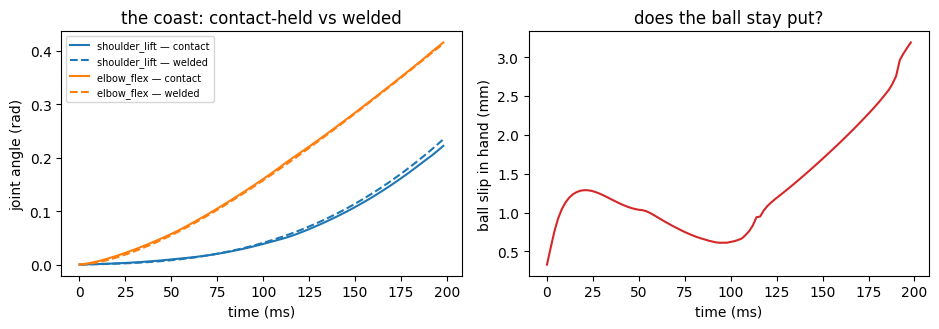

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
t_ms = np.arange(100) * 2.0
for j, name, color in ((1, "shoulder_lift", "C0"), (2, "elbow_flex", "C1")):
    axes[0].plot(t_ms, contact_q[:, j], color=color, label=f"{name} — contact")
    axes[0].plot(t_ms, weld_q[:, j], color=color, ls="--", label=f"{name} — welded")
axes[0].set_xlabel("time (ms)")
axes[0].set_ylabel("joint angle (rad)")
axes[0].set_title("the coast: contact-held vs welded")
axes[0].legend(fontsize=7)
axes[1].plot(t_ms, slip_mm, color="C3")
axes[1].set_xlabel("time (ms)")
axes[1].set_ylabel("ball slip in hand (mm)")
axes[1].set_title("does the ball stay put?")
plt.tight_layout()
plt.show()

### Watch the probe — grasp and coast, simulated

The clip below **is the contact simulation**: the jaw closes under its
position servo, the ball seats into the pads, then the kick — jaw angle and
ball pose both come from the physics, not from art direction. Roughly 5×
slow motion; the encoders are read in the final 0.2 s.


wrote media/same_pixels_heft_probe.gif (50 frames — contact-simulated)


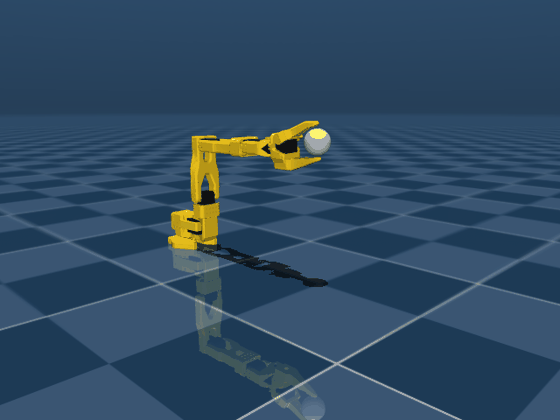

In [8]:
from _robot_render import TrajectoryRenderer, write_gif
from IPython.display import Image as IPyImage

heft_renderer = TrajectoryRenderer("so101_mjcf", arm_g.to_mjcf(), size=(640, 480))
# last 0.3 s of the close + the full 0.2 s probe, from the recorded history
hist = grasp_hist[750:]
STRIDE_H = 5
qpos_hist = np.asarray([h[0] for h in hist])
ball_hist = np.asarray([h[1] for h in hist])[::STRIDE_H]
_ctr = dict(i=0)


def _heft_overlay(scene, data, q):
    i = min(_ctr["i"], len(ball_hist) - 1)
    _ctr["i"] += 1
    g = scene.geoms[scene.ngeom]
    mujoco.mjv_initGeom(
        g,
        mujoco.mjtGeom.mjGEOM_SPHERE,
        np.array([0.023, 0.0, 0.0]),
        ball_hist[i],
        np.eye(3).ravel(),
        np.array([0.85, 0.83, 0.80, 1.0], np.float32),
    )
    scene.ngeom += 1


heft_frames = heft_renderer.render(
    qpos_hist,
    camera=dict(distance=0.95, azimuth=135, elevation=-12, lookat=(0.3, 0.0, 0.12)),
    stride=STRIDE_H,
    overlay=_heft_overlay,
)
gif_heft = write_gif(heft_frames, "media/same_pixels_heft_probe.gif", width=560, fps=16)
print("wrote", gif_heft, f"({len(heft_frames)} frames — contact-simulated)")
IPyImage(filename=gif_heft)

In [9]:
fits = {}
for k, link in balls.items():
    t0 = time.time()
    fits[k] = identify_payload(arm, link, prior, excitation=probe, iterations=12)
    r = fits[k]
    m = float(r.fitted["payload.mass"])
    com = np.asarray(r.fitted["payload.com"])
    print(
        f"ball {k} ({time.time() - t0:.0f} s): "
        f"mass {m:.4f} kg (true {TRUE[k]['mass']}), "
        f"com {np.round(com * 1000, 1)} mm "
        f"(true {np.round(np.array(TRUE[k]['com']) * 1000, 1)}), "
        f"warnings: {r.warnings or 'none'}"
    )

ball S (340 s): mass 0.3000 kg (true 0.3), com [ 2. -5. 12.] mm (true [ 2. -5. 12.]), warnings: none


ball H (327 s): mass 0.0400 kg (true 0.04), com [-0. -0.  3.] mm (true [0. 0. 3.]), warnings: ('identify_payload: payload.com[0] is unresolved — standard error 9.53e-06 exceeds 100% of the fitted value 1.17e-06. Do not trust the point estimate; use a richer probe or lower-noise telemetry.', 'identify_payload: payload.com[1] is unresolved — standard error 1.67e-05 exceeds 100% of the fitted value 1.11e-05. Do not trust the point estimate; use a richer probe or lower-noise telemetry.')


ball S: mass = 0.30002 ± 0.00003 kg (±2σ), CoM z = 12.00 ± 0.008 mm
ball H: mass = 0.04001 ± 0.00001 kg (±2σ), CoM z = 3.00 ± 0.020 mm


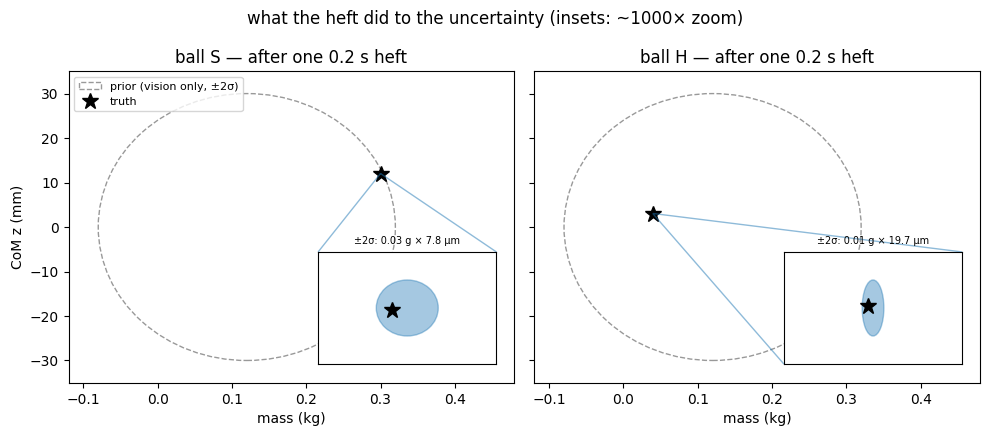

In [10]:
# The collapse: vision's prior uncertainty vs the post-heft marginal ±2σ.
# The posterior is so much tighter that it is invisible at the prior's scale —
# each panel gets a zoom inset (that invisibility IS the result).
from matplotlib.patches import Ellipse

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
PRIOR_SD_MASS, PRIOR_SD_COMZ = 0.10, 0.015  # what "a ball this size" leaves open
for ax, k in zip(axes, fits):
    r = fits[k]
    m = float(r.fitted["payload.mass"])
    cz_mm = float(np.asarray(r.fitted["payload.com"])[2]) * 1000
    sd_m = float(np.sqrt(max(r.covariance["payload.mass"], 0.0)))
    sd_z_mm = float(np.sqrt(max(r.covariance["payload.com[2]"], 0.0))) * 1000
    ax.add_patch(
        Ellipse(
            (prior.mass, 0.0),
            2 * 2 * PRIOR_SD_MASS,
            2 * 2 * PRIOR_SD_COMZ * 1000,
            fc="none",
            ec="0.6",
            ls="--",
            label="prior (vision only, ±2σ)",
        )
    )
    ax.plot(
        TRUE[k]["mass"], TRUE[k]["com"][2] * 1000, "k*", ms=12, label="truth", zorder=4
    )
    # zoom inset around the posterior (~1000× tighter than the prior)
    half_m = max(4 * sd_m, 1e-4)
    half_z = max(4 * sd_z_mm, 1e-3)
    axins = ax.inset_axes(
        [0.56, 0.06, 0.4, 0.36],
        xlim=(m - half_m, m + half_m),
        ylim=(cz_mm - half_z, cz_mm + half_z),
    )
    axins.add_patch(
        Ellipse((m, cz_mm), 2 * 2 * sd_m, 2 * 2 * sd_z_mm, fc="C0", alpha=0.4, ec="C0")
    )
    axins.plot(TRUE[k]["mass"], TRUE[k]["com"][2] * 1000, "k*", ms=12)
    axins.set_xticks([])
    axins.set_yticks([])
    axins.set_title(
        f"±2σ: {2 * sd_m * 1000:.2f} g × {2 * sd_z_mm * 1000:.1f} µm", fontsize=7
    )
    ax.indicate_inset_zoom(axins, edgecolor="C0")
    ax.set_title(f"ball {k} — after one 0.2 s heft")
    ax.set_xlabel("mass (kg)")
    print(
        f"ball {k}: mass = {m:.5f} ± {2 * sd_m:.5f} kg (±2σ), "
        f"CoM z = {cz_mm:.2f} ± {2 * sd_z_mm:.3f} mm"
    )
axes[0].set_ylabel("CoM z (mm)")
axes[0].set_xlim(-0.12, 0.48)
axes[0].set_ylim(-35, 35)
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("what the heft did to the uncertainty (insets: ~1000× zoom)")
plt.tight_layout()
plt.show()

## Act 3 — choosing the next poke

Not every poke is equally informative. `design_probe` differentiates the
probe's predicted Fisher information **with respect to the probe itself**
(forward-over-forward autodiff through the simulation) and ascends — and
with a previous fit's covariance it targets exactly the directions that fit
left widest. Demonstrated on the light cartpole model (the second-order
compile on a 6-DOF arm runs minutes-to-hours — a documented cost, see
KNOWN_GAPS): a mass clamped to the pole tip, a deliberately weak starting
probe, and the gradient finds a strictly better one.


In [11]:
cartpole = zoo.load("cartpole")
tip = RigidPayload(attach_link="pole", mass=0.05, offset=(0.0, 0.0, 0.6))

# The hard verdict, structurally: on this 2-DOF robot a single quasi-static
# sample cannot pin 7 payload parameters — refused BEFORE any fit.
degenerate = Excitation(q0=(0.0, 0.0), qd0=(0.0, 0.0), sample_times=(0.001,))
report = payload_identifiability(
    cartpole, tip, degenerate, fit=("mass", "com", "inertia_diag")
)
print(
    f"quasi-static on cartpole: identifiable={report.identifiable} "
    f"(rank {report.rank}/{len(report.names)})"
)

weak = design_coast_excitation(cartpole, speed=0.02, sample_times=(0.05, 0.1))

t0 = time.time()
better = design_probe(cartpole, tip, fit=("mass",), excitation0=weak)
info_weak = probe_information(cartpole, tip, weak, fit=("mass",))
info_opt = probe_information(cartpole, tip, better, fit=("mass",))
print(
    f"designed in {time.time() - t0:.0f} s: "
    f"logdet Fisher {info_weak:.2f} -> {info_opt:.2f} "
    f"(kick {np.round(weak.qd0, 3)} -> {np.round(better.qd0, 3)})"
)


# And the information difference is not cosmetic — it is posterior width:
def cov_with(exc):
    link = PayloadLoopbackLink(cartpole, tip, true_mass=0.2, seed=3, noise_std=1e-4)
    return identify_payload(
        cartpole, link, tip, excitation=exc, fit=("mass",)
    ).covariance["payload.mass"]


print(
    f"posterior var(mass): weak probe {cov_with(weak):.3e}  "
    f"designed probe {cov_with(better):.3e}"
)

quasi-static on cartpole: identifiable=False (rank 1/7)


designed in 135 s: logdet Fisher -20.13 -> -2.05 (kick [0.02 0.02] -> [ 0.02  12.058])


posterior var(mass): weak probe 7.478e-02  designed probe 5.155e-10


## Act 4 — the corrected throw

Re-tune the two knobs on the **identified** model — not the truth, which no
one outside this notebook knows — and throw the true balls again.


In [12]:
corrected, knobs = {}, {}
for k, r in fits.items():
    fitted_model = throw_model(
        float(r.fitted["payload.mass"]),
        tuple(np.asarray(r.fitted["payload.com"])),
    )
    aim_k, power_k = tune(*fitted_model, TARGET, power0=power_blind)
    knobs[k] = (aim_k, power_k)
    corrected[k] = throw_land(*models_true[k], aim_k, power_k)
    print(
        f"ball {k}: corrected throw lands at {np.round(corrected[k], 3)} — "
        f"miss {np.linalg.norm(corrected[k] - TARGET) * 100:.2f} cm "
        f"(blind: {np.linalg.norm(blind[k] - TARGET) * 100:.1f} cm)"
    )

ball S: corrected throw lands at [0.28 0.42] — miss 0.00 cm (blind: 11.9 cm)


ball H: corrected throw lands at [0.28 0.42] — miss 0.00 cm (blind: 4.9 cm)


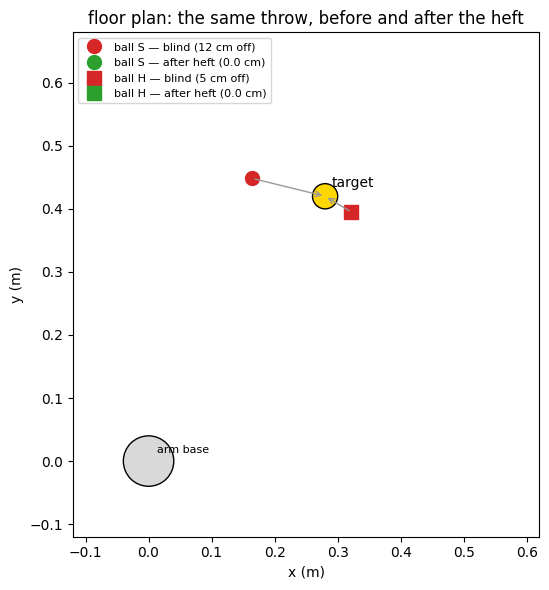

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.add_patch(plt.Circle(TARGET, 0.02, fc="gold", ec="k", zorder=3))
ax.annotate("target", TARGET, xytext=(5, 7), textcoords="offset points")
base = plt.Circle((0, 0), 0.04, fc="0.85", ec="k")
ax.add_patch(base)
ax.annotate("arm base", (0, 0), xytext=(6, 6), textcoords="offset points", fontsize=8)
for k, marker in (("S", "o"), ("H", "s")):
    b, c = blind[k], corrected[k]
    ax.plot(
        *b,
        marker,
        color="C3",
        ms=10,
        label=f"ball {k} — blind ({np.linalg.norm(b - TARGET) * 100:.0f} cm off)",
    )
    ax.plot(
        *c,
        marker,
        color="C2",
        ms=10,
        label=f"ball {k} — after heft ({np.linalg.norm(c - TARGET) * 100:.1f} cm)",
    )
    ax.annotate("", xy=c, xytext=b, arrowprops=dict(arrowstyle="->", color="0.6", lw=1))
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("floor plan: the same throw, before and after the heft")
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="upper left")
ax.set_xlim(-0.12, 0.62)
ax.set_ylim(-0.12, 0.68)
plt.tight_layout()
plt.show()

### Watch it — the rendered throw

The same four throws through the full-mesh SO-101 scene (post-hoc kinematic
render, `_robot_render.py` — MuJoCo does no physics here). All four run on a
synchronized clock, ~3× slow motion: top row ball S, bottom row ball H;
left the blind throw, right the corrected one. Both balls are drawn
identically — that is the point.


wrote media/same_pixels_different_physics.gif (48 frames)


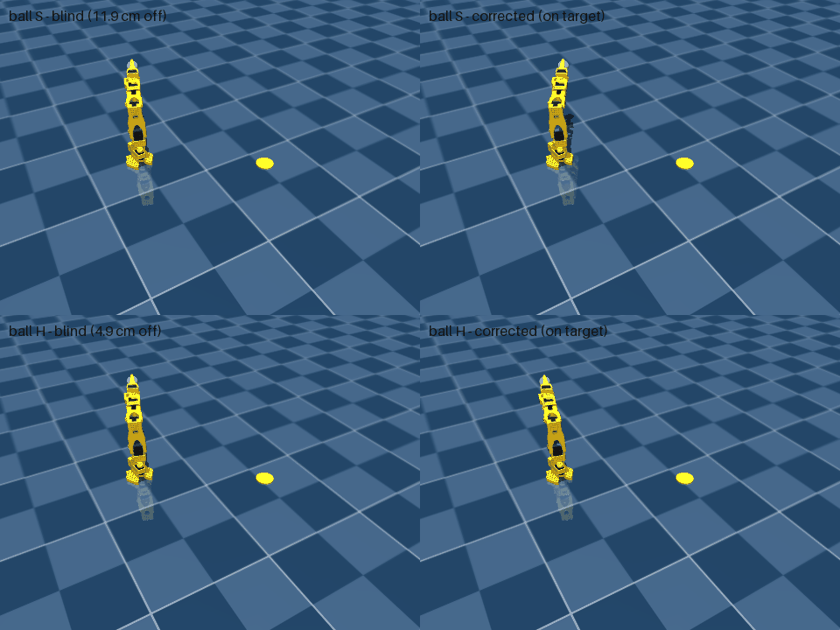

In [14]:
from _robot_render import TrajectoryRenderer, write_gif
from IPython.display import Image as IPyImage
from PIL import Image, ImageDraw, ImageFont

CAM = dict(distance=1.5, azimuth=150, elevation=-38, lookat=(0.16, 0.24, 0.02))
BALL_RGBA = (0.85, 0.83, 0.80, 1.0)  # both balls identical — same pixels
STRIDE = 3  # 3x slow-mo at 20 fps
renderer = TrajectoryRenderer("so101_mjcf", arm.to_mjcf(), size=(480, 360))


def throw_clip(k, aim, power, marker_rgba):
    """Frames for one throw: spin-up to release, ballistic flight, landing."""
    rollout, mj = models_true[k]
    theta = aim + np.asarray(rollout(power))[:, 0]  # aim folds into the pan angle
    # Ball world position while held: FK of the payload body per pan angle.
    d = mujoco.MjData(mj)
    bid = mj.body("payload").id
    held = []
    for th in theta[: K_REL + 2]:
        d.qpos[:] = [th]
        mujoco.mj_forward(mj, d)
        held.append(d.xpos[bid].copy())
    held = np.asarray(held)
    p, v = held[K_REL], (held[K_REL + 1] - held[K_REL - 1]) / (2 * DT)
    tf = (v[2] + np.sqrt(max(v[2] ** 2 + 2 * G * p[2], 0.0))) / G
    t_fly = np.arange(DT, tf + DT, DT)
    flight = p[None, :] + v[None, :] * t_fly[:, None]
    flight[:, 2] -= 0.5 * G * t_fly**2
    land = flight[-1].copy()
    land[2] = 0.0
    rest = land + np.array([0.0, 0.0, 0.023])  # ball at rest on the floor
    ball = np.vstack([held[: K_REL + 1], flight, np.repeat(rest[None, :], 12, axis=0)])

    # Arm poses: pan spins to release, then freezes while the ball flies.
    n_total = ball.shape[0]
    pan = np.concatenate(
        [theta[: K_REL + 1], np.full(n_total - K_REL - 1, theta[K_REL])]
    )
    qpos = np.zeros((n_total, 6))
    qpos[:, 0] = pan
    qpos[:, 5] = gq_settled  # jaw at the contact-settled grasp angle (display)

    frame_ball = ball[::STRIDE]
    landed_from = (K_REL + len(t_fly)) // STRIDE
    counter = dict(i=0)

    def overlay(scene, data, q):
        i = counter["i"]
        counter["i"] += 1

        def blob(kind, pos, size, rgba):
            if scene.ngeom >= scene.maxgeom:
                return
            g = scene.geoms[scene.ngeom]
            mujoco.mjv_initGeom(
                g,
                kind,
                np.asarray(size, float),
                np.asarray(pos, float),
                np.eye(3).ravel(),
                np.asarray(rgba, np.float32),
            )
            scene.ngeom += 1

        blob(
            mujoco.mjtGeom.mjGEOM_CYLINDER,
            (*TARGET, 0.002),
            (0.035, 0.002, 0),
            (0.95, 0.78, 0.12, 1.0),
        )  # target disc
        j = min(i, len(frame_ball) - 1)
        blob(
            mujoco.mjtGeom.mjGEOM_SPHERE, frame_ball[j], (0.023, 0, 0), BALL_RGBA
        )  # the ball
        if i >= landed_from:
            blob(
                mujoco.mjtGeom.mjGEOM_CYLINDER,
                land + [0, 0, 0.003],
                (0.028, 0.003, 0),
                marker_rgba,
            )  # landing mark

    frames = renderer.render(qpos, camera=CAM, stride=STRIDE, overlay=overlay)
    return frames


clips, labels = [], []
for k in TRUE:
    for mode in ("blind", "corrected"):
        aim, power = (aim_blind, power_blind) if mode == "blind" else knobs[k]
        rgba = (0.85, 0.2, 0.15, 1.0) if mode == "blind" else (0.2, 0.7, 0.25, 1.0)
        clips.append(throw_clip(k, aim, power, rgba))
        miss = (
            np.linalg.norm((blind if mode == "blind" else corrected)[k] - TARGET) * 100
        )
        labels.append(
            f"ball {k} - {mode} ({miss:.1f} cm off)"
            if miss >= 0.05
            else f"ball {k} - {mode} (on target)"
        )

# Compose the 2x2 grid on a shared clock (pad shorter clips with their end).
n = max(len(c) for c in clips) + 8
try:
    font = ImageFont.load_default(size=16)
except TypeError:  # older Pillow
    font = ImageFont.load_default()
grid_frames = []
for i in range(n):
    canvas = Image.new("RGB", (960, 720))
    for j, (clip, label) in enumerate(zip(clips, labels)):
        tile = Image.fromarray(clip[min(i, len(clip) - 1)])
        x, y = (j % 2) * 480, (j // 2) * 360
        canvas.paste(tile, (x, y))
        ImageDraw.Draw(canvas).text(
            (x + 10, y + 8), label, fill=(20, 20, 20), font=font
        )
    grid_frames.append(np.asarray(canvas))

gif_path = write_gif(
    grid_frames, "media/same_pixels_different_physics.gif", width=840, fps=20
)
print("wrote", gif_path, f"({len(grid_frames)} frames)")
IPyImage(filename=gif_path)

## Act 5 — other senses: toss and squeeze

Mass is not the only invisible parameter. A short toss-and-bounce gives the
**coefficient of restitution** — fitted with gradients taken *through the
impacts* (jaxonomy's saltation lane, FD-verified); a squeeze gives contact
**stiffness and damping**. Both refuse under-determined records by name.


In [15]:
# Toss: five impact times (as a contact mic or camera would give you).
rng = np.random.default_rng(0)
true_e, drop = 0.72, 0.35
ticks = predict_bounce_times(true_e, drop, 5) + rng.normal(0, 2e-4, 5)
r_toss = identify_restitution(np.sort(ticks))
print(
    f"restitution: {float(r_toss.fitted['object.restitution']):.3f} "
    f"(true {true_e}), drop height "
    f"{float(r_toss.fitted['object.drop_height']) * 100:.1f} cm "
    f"(true {drop * 100:.0f})"
)

# One bounce + unknown height is refused, not silently fitted:
try:
    identify_restitution(ticks[:1])
except Exception as e:
    print("single bounce ->", str(e).splitlines()[0])

# Squeeze: half-sine compression, F = k·x + c·x·ẋ.
t = np.linspace(0, 1, 300)
x = 0.008 * np.sin(np.pi * t)
xd = 0.008 * np.pi * np.cos(np.pi * t)
force = 900.0 * x + 250.0 * x * xd + rng.normal(0, 0.01, t.size)
r_sq = identify_squeeze(x, xd, force)
print(
    f"squeeze: k = {float(r_sq.fitted['object.stiffness']):.0f} N/m "
    f"(true 900), c = {float(r_sq.fitted['object.damping']):.0f} N·s/m² "
    f"(true 250)"
)

restitution: 0.720 (true 0.72), drop height 35.0 cm (true 35)
single bounce -> identify_restitution: 1 impact time(s) cannot pin 2 parameter(s) (object.restitution, object.drop_height). Record more bounces or pass a known drop height h0.
squeeze: k = 900 N/m (true 900), c = 262 N·s/m² (true 250)


## Act 6 — per-object attestation

The fit is not just numbers — it re-attests the unit. The same arm holding
two different balls (or the same ball re-identified) is a **different
attested configuration**: a preflight pass bound to one handle does not
vouch for another.


In [16]:
from jaxterity.twin import so101_twin

twin = so101_twin("SN-DEMO-001")
handles = {"bare arm": twin.attestation_handle}
for k, r in fits.items():
    handles[f"holding ball {k}"] = twin.with_payload(prior, r).attestation_handle
for name, h in handles.items():
    print(f"{name:18s} {h[:24]}…")
assert len(set(handles.values())) == len(handles)
print(f"\ntotal runtime: {(time.time() - t_start) / 60:.1f} min")

bare arm           8ac64accd937bfa89e079ffe…
holding ball S     ccab00142cc27f200586355e…
holding ball H     c0f8e5c1e82ffc9805f82474…

total runtime: 18.7 min


## Building intuition — you already own this sensor

Everything above is something your own hand does without asking.

**The measurement.** Close your eyes and lift a coffee cup — you can still
tell whether it is full or empty. Not by sight, and not with a scale in
your fingertips: your muscles and joints report back *how the arm actually
moved* versus how you told it to move. That joint-angle sense
(proprioception) is exactly what the robot reads — its encoders. Nothing
else.

**The expectation.** Your brain has already predicted the lift: *"I know my
own arm — its weight, its strength, its friction — so this much effort
should raise my hand like so."* You spent a lifetime calibrating that
self-model. The robot's version is the calibrated arm.

**The surprise is the object.** The hand rises slower than predicted. Your
arm is known; gravity is known; the only thing left to explain the
difference is the thing you are holding. *Measurement minus expectation =
the object.* That is the entire fit, in one sentence.

**Where the weight sits.** Hold a hammer by the handle: it does not just
feel heavy, it *twists* your wrist — and the twist changes as you tilt it.
That is the centre of mass talking. The ball tugs differently on
different joints in different poses; each pose is another clue.

**Why the wiggle is gentle.** You heft a package with a small bob, not by
hurling it — a slow lift already reveals weight and balance. But a slow
heft tells you *nothing* about how hard the object is to spin; for that
you would have to twirl it. The identifiability report is the robot
knowing this about itself — before moving — and refusing to answer
questions the probe cannot ask.

**The confidence.** Heft a ping-pong ball: you can tell it is light, but
not whether its weight is a millimetre off-centre — your hand cannot feel
that fine. The robot hits the same wall and *says so*: the hollow ball's
micrometre-scale CoM components came back flagged, not faked.

**The oven mitt.** Lift the cup through a thick mitt and everything feels
mushier and lighter than it is. That is the rigid-weld assumption's
failure mode: a soft grasp biases the fit (a known gap).

**The fatigued arm.** And the quiet punchline: if your own muscles are
weaker than you believe — miscalibrated — you misjudge *every* object you
pick up, no matter how carefully you heft. The scale itself is off. The
robot is no different: the payload estimate is only as good as the arm's
knowledge of itself. That is why per-unit calibration and system
identification are not a preliminary chore here but the load-bearing
layer — the heft works because the arm was made to know itself first.


## What this demo is not

- **Not hardware.** The "real" balls are planted-parameter loopbacks; the
  hardware path is the same telemetry channel via `ReplayLink` + a real
  LeKiwi/SO-101 capture, and until that exists this is a simulation-tier
  result (CLAIMS C-120..C-122 are scoped accordingly).
- **Not vision.** Extracting geometry, impact times, or squeeze traces from
  cameras/sensors is outside this stack today.
- **Contact is simulated only where it says so.** The identification and the
  throws use the declared rigid weld; the Act-2 grasp section holds the same
  probe through stock-MuJoCo contact physics and measures what the weld
  costs (mm-scale ball settle, fraction-of-a-degree coast deviation on the
  main arm joints, ~3° on wrist_roll). A *soft or slipping* grasp on real hardware would still bias
  the fit — a known gap.

What it *is*: the missing sense for the parameters pixels cannot carry —
identifiability-gated, bound-projected, uncertainty-quantified, and attested
per object.
